# Part 1: Data Cleaning and Validation
## Set up:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from contextlib import closing
from pathlib import Path
from IPython.display import display
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

db_path = Path('data/data.db')
price_cols = ['open', 'high', 'low', 'close']
key = ['ticker', 'ts']

## 1.1 Load and Inspect the Data
### Load and display the basic stats

In [2]:

with closing(sqlite3.connect(db_path.resolve().as_uri() + '?mode=ro', uri=True)) as conn:
    raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn, parse_dates=['ts'])
    reference = pd.read_sql_query('SELECT ticker, ts, close, adj_close FROM ohlc', conn, parse_dates=['ts'])

raw.info()
display(raw.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   ts         397711 non-null  datetime64[ns]
 1   open       397711 non-null  float64       
 2   high       397711 non-null  float64       
 3   low        397711 non-null  float64       
 4   close      397711 non-null  float64       
 5   adj_close  377856 non-null  float64       
 6   volume     397711 non-null  int64         
 7   ticker     397711 non-null  object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 24.3+ MB


,ts,open,high,low,close,adj_close,volume
count,397711,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,1998-04-17 21:18:45.292485888,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
min,1962-01-02 00:00:00,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,1985-05-28 00:00:00,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,2000-01-06 00:00:00,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,2012-08-21 00:00:00,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,2024-12-06 00:00:00,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09
std,NaN,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08


### Identify the columns and their meanings

In [3]:
display(pd.Series({
    'ts': 'Observation (trading) date',
    'ticker': 'Stock symbol (needs normalizing)',
    'open / high / low / close': 'Raw daily prices',
    'adj_close': 'Vendor close adjusted for splits and dividends',
    'volume': 'Shares traded that day',
}, name='meaning').to_frame())

,meaning
ts,Observation (trading) date
ticker,Stock symbol (needs normalizing)
open / high / low / close,Raw daily prices
adj_close,Vendor close adjusted for splits and dividends
volume,Shares traded that day


### The date range and list of tickers

In [4]:
print('Date range:', raw['ts'].min().date(), 'to', raw['ts'].max().date())
print('Raw ticker labels:', raw['ticker'].nunique(), '| Examples:', raw['ticker'].unique()[:3])
display(raw.isna().sum().rename('missing'))

Date range: 1962-01-02 to 2024-12-06
Raw ticker labels: 150 | Examples: ['CAT' 'CVX' 'HD']


ts               0
open             0
high             0
low              0
close            0
adj_close    19855
volume           0
ticker           0
Name: missing, dtype: int64

### Normalize the tickers

In [5]:
# correct ticker labels:
def normalize_ticker(labels):
    """Remove HTML markup and whitespace, then upper-case each ticker label."""
    return (labels.astype('string')
            .str.replace(r'<[^>]+>', '', regex=True)
            .str.strip().str.upper())

data = raw.copy()
data['raw_ticker'] = data['ticker']
data['ticker'] = normalize_ticker(data['ticker'])
print(f"Raw labels: {raw['ticker'].nunique()}, Normalized tickers: {data['ticker'].nunique()}")
print('Tickers:', sorted(data['ticker'].unique()))

Raw labels: 150, Normalized tickers: 30
Tickers: ['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


In [6]:
# Quick audit of the normalized tickers:
ticker_audit = data.groupby(['ticker', 'raw_ticker']).size().rename('rows').reset_index()
display(ticker_audit.head(10))

,ticker,raw_ticker,rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264
4,AAPL,AAPL,10747
5,AMGN,"<a target=""_blank""><span style=""color: blue"">A...",294
6,AMGN,"<a target=""_blank""><span style=""color: red"">AM...",290
7,AMGN,"<a target=""_blank""><span style=""font-weight: b...",280
8,AMGN,"<a target=""_blank""><span style=""font-weight: b...",272
9,AMGN,AMGN,10154


### Locate duplications and conflicts

In [7]:
value_cols = ['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume']
exact_duplicate = data.duplicated(value_cols, keep='first')
deduplicated = data.loc[~exact_duplicate].sort_values(key).reset_index(drop=True)
# check for key = (ticker, ts) same but price not the same
conflicting = deduplicated.duplicated(key, keep=False)
print('Exact duplicate records:', exact_duplicate.sum())
print('Rows in conflicting (ticker, ts) keys:', conflicting.sum())
display(data.loc[data.duplicated(key, keep=False)].sort_values(key).head(6))

Exact duplicate records: 29460
Rows in conflicting (ticker, ts) keys: 0


,ts,open,high,low,close,adj_close,volume,ticker,raw_ticker
183610,1981-01-02,0.15402,0.15402,0.15402,0.15402,0.118730,21660820,AAPL,AAPL
218476,1981-01-02,0.15402,0.15402,0.15402,0.15402,0.118730,21660820,AAPL,AAPL
94535,1981-01-05,0.15067,0.15067,0.15067,0.15067,0.116150,35728032,AAPL,AAPL
343474,1981-01-05,0.15067,0.15067,0.15067,0.15067,0.116150,35728032,AAPL,AAPL
26868,1981-02-10,0.12165,0.12165,0.12165,0.12165,0.093779,18345616,AAPL,AAPL
251636,1981-02-10,0.12165,0.12165,0.12165,0.12165,0.093779,18345616,AAPL,AAPL


## 1.2 Detect Data Quality Issues
### Severity standard

Severity ranks how much an issue threatens the prices used for returns in Part 2:

- **high** : a raw or adjusted price is missing, invalid, or internally impossible. Returns cannot be trusted until it is repaired or quarantined.
- **medium** : a problem that does not by itself make a price wrong: a record-level issue that is fixed deterministically (formatting, duplicates, volume) or only reported (absent rows), or a review flag whose value may be genuine (zero volume, extreme return).

| issue_type | severity | reason |
|---|---|---|
| `missing_open/high/low/close/adj_close` | high | No price, so no return for that day |
| `missing_volume` | medium | Volume is not used for returns; set to 0 with a repair flag |
| `missing_session` | medium | Absent row on a reference trading date; not filled with invented prices |
| `extreme_return` | medium | Retrospective 3-std screen, a review flag rather than a deletion rule; kept and checked against `ohlc` in the cleaning step |
| `high_below_close`, `low_above_close` | high | Impossible close vs high/low: at least one price is wrong |
| `invalid_price` | high | Nonpositive or non-finite prices make returns undefined |
| `open_out_of_range`, `close_out_of_range` | high | open or close outside [low, high]: at least one price is wrong |
| `high_below_low` | high | Impossible range: at least one price is wrong |
| `zero_volume` | medium | May be stale data or a real no-trade day; kept |
| `negative_volume` | medium | Impossible, but volume is not used for returns; set to 0 with a repair flag |
| `ticker_markup` | medium | HTML/whitespace in the label; fixed by normalization, prices unaffected |
| `duplicate_record` | medium | Exact repeat; dropping it loses no information |

### 1.2.1 Define the Functions
#### Detect **Missing Data**:
##### Identify the missing values in each column:

In [8]:
def missing_value_report(frame):
    """One issue row per missing or non-finite cell in the price and volume columns."""
    parts = []
    for col in price_cols + ['adj_close', 'volume']:
        rows = frame.loc[~np.isfinite(frame[col]), ['ticker', 'ts']].rename(columns={'ts': 'issue_date'})
        rows['issue_type'] = f'missing_{col}'
        rows['description'] = f'{col} is missing or non-finite'
        rows['severity'] = 'high' if col in price_cols + ['adj_close'] else 'medium'
        parts.append(rows)
    return pd.concat(parts, ignore_index=True)

##### Detect missing trading days and create the summary:
Expected dates are each ticker's dates over its full `ohlc` history, so a missing first or last day is caught too.

In [9]:
def missing_sessions(frame, expected_dates):
    """Return expected dates absent from one ticker's observations."""
    observed = pd.DatetimeIndex(frame['ts'].dropna().unique())
    return pd.DatetimeIndex(expected_dates).difference(observed).sort_values()


def missing_session_report(frame, reference_keys):
    """Compare each ticker with all of its ohlc reference dates, so a missing first or last day also counts."""
    parts = []
    for ticker, rows in frame.groupby('ticker'):
        expected = reference_keys.loc[reference_keys['ticker'].eq(ticker), 'ts']
        start, end = expected.min(), expected.max()
        gaps = missing_sessions(rows, expected)
        print(f'Ticker {ticker} is missing {len(gaps)} trading days between {start.date()} and {end.date()}')
        parts.append(pd.DataFrame({'ticker': ticker, 'issue_type': 'missing_session', 'issue_date': gaps,
                                   'description': 'Date in ohlc reference but absent from ohlc_hw',
                                   'severity': 'medium'}))
    return pd.concat(parts, ignore_index=True)

#### Outliers and Inconsistency Issues:

In [10]:
# Helper for the outlier and inconsistency reports:
def issue_rows(data, masks, descriptions, severity):
    """Turn {issue_type: mask} into Data Quality Report rows."""
    parts = []
    for issue, mask in masks.items():
        rows = data.loc[mask, ['ticker', 'ts']].rename(columns={'ts': 'issue_date'})
        rows['issue_type'] = issue
        rows['description'] = descriptions[issue]
        rows['severity'] = severity.get(issue, 'high')
        parts.append(rows)
    return pd.concat(parts, ignore_index=True)

##### Detect **Outliers**:

In [11]:
def outlier_report(frame):
    """Outliers: extreme close returns, high/low vs close, nonpositive or non-finite prices."""
    data = frame.sort_values(key).copy()
    equity_cols = price_cols + ['adj_close']
    valid_close = data['close'].where(np.isfinite(data['close']) & data['close'].gt(0))
    returns = valid_close.groupby(data['ticker']).pct_change(fill_method=None)
    grouped = returns.groupby(data['ticker'])
    mean, std = grouped.transform('mean'), grouped.transform('std')  # sample std, ddof=1
    present = data[equity_cols].notna()
    masks = {
        'extreme_return': returns.notna() & std.gt(0) & (returns - mean).abs().gt(3 * std),
        'high_below_close': data['high'].lt(data['close']),
        'low_above_close': data['low'].gt(data['close']),
        'invalid_price': (present & (~np.isfinite(data[equity_cols]) | data[equity_cols].le(0))).any(axis=1),
    }
    descriptions = {
        'extreme_return': '|close return - mean| > 3 sample std (review flag)',
        'high_below_close': 'high < close (impossible)',
        'low_above_close': 'low > close (impossible)',
        'invalid_price': 'Nonpositive or non-finite price (incl. adj_close)',
    }
    return issue_rows(data, masks, descriptions, {'extreme_return': 'medium'})

##### Detect **Inconsistencies**:


In [12]:
def inconsistency_report(frame):
    """Inconsistencies: high < low, open or close outside [low, high], zero or negative volume."""
    masks = {
        'high_below_low': frame['high'].lt(frame['low']),
        'open_out_of_range': frame['open'].lt(frame['low']) | frame['open'].gt(frame['high']),
        'close_out_of_range': frame['close'].lt(frame['low']) | frame['close'].gt(frame['high']),
        'zero_volume': frame['volume'].eq(0),
        'negative_volume': frame['volume'].lt(0),
    }
    descriptions = {
        'high_below_low': 'high < low (impossible)',
        'open_out_of_range': 'open outside [low, high]',
        'close_out_of_range': 'close outside [low, high]',
        'zero_volume': 'Zero volume (possibly stale)',
        'negative_volume': 'Negative volume (impossible)',
    }
    return issue_rows(frame, masks, descriptions, {'zero_volume': 'medium', 'negative_volume': 'medium'})

### 1.2.2 Deliberate Demo Validation:
Injected cases for checks that can find zero issues in `ohlc_hw`: 

- 2023-12-29, 01-04 and 01-12 absent from the data (first, middle and last trading day);

- 01-02 missing `high` on the first day (a leading gap); 

- 01-03 `high < close`; 

- 01-05 `low > close`;

- 01-08 all prices missing; 

- 01-09 nonpositive close and missing volume; 

- 01-10 missing `open`, infinite `adj_close` and negative volume;

- 01-11 two conflicting rows.

In [13]:
demo = pd.DataFrame({
    'ticker': ['DEMO'] * 8,
    'ts': pd.to_datetime(['2024-01-02', '2024-01-03', '2024-01-05', '2024-01-08', '2024-01-09', '2024-01-10',
                          '2024-01-11', '2024-01-11']),
    'open': [100.0, 101.0, 102.0, np.nan, 103.0, np.nan, 105.0, 105.0],
    'high': [np.nan, 100.0, 104.0, np.nan, 105.0, 106.0, 107.0, 107.0],
    'low': [99.0, 99.0, 103.5, np.nan, 102.0, 103.0, 104.0, 104.0],
    'close': [101.0, 100.5, 103.0, np.nan, -1.0, 105.0, 106.0, 106.5],
    'adj_close': [101.0, 100.5, 103.0, np.nan, np.nan, np.inf, 106.0, 106.5],
    'volume': [1000.0, 0.0, 1200.0, 900.0, np.nan, -1100.0, 1000.0, 1000.0],
})
demo_reference = pd.DataFrame({'ticker': 'DEMO',
    'ts': pd.to_datetime(['2023-12-29', '2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05',
                          '2024-01-08', '2024-01-09', '2024-01-10', '2024-01-11', '2024-01-12']),
    'close': [100.0, 101.0, 100.5, 102.0, 103.0, 104.0, 104.5, 105.0, 106.0, 107.0]})
demo_reference['adj_close'] = demo_reference['close']
demo_gaps = missing_session_report(demo, demo_reference[key])
removed_dates = pd.to_datetime(['2023-12-29', '2024-01-04', '2024-01-12'])  # first, middle and last day
assert demo_gaps['issue_date'].tolist() == removed_dates.tolist()
demo_issues = pd.concat([missing_value_report(demo), demo_gaps, outlier_report(demo), inconsistency_report(demo)])
display(demo_issues.sort_values('issue_date', kind='stable').reset_index(drop=True))

Ticker DEMO is missing 3 trading days between 2023-12-29 and 2024-01-12


,ticker,issue_date,issue_type,description,severity
0,DEMO,2023-12-29,missing_session,Date in ohlc reference but absent from ohlc_hw,medium
1,DEMO,2024-01-02,missing_high,high is missing or non-finite,high
2,DEMO,2024-01-03,high_below_close,high < close (impossible),high
3,DEMO,2024-01-03,open_out_of_range,"open outside [low, high]",high
4,DEMO,2024-01-03,close_out_of_range,"close outside [low, high]",high
5,DEMO,2024-01-03,zero_volume,Zero volume (possibly stale),medium
6,DEMO,2024-01-04,missing_session,Date in ohlc reference but absent from ohlc_hw,medium
7,DEMO,2024-01-05,low_above_close,low > close (impossible),high
8,DEMO,2024-01-05,open_out_of_range,"open outside [low, high]",high
9,DEMO,2024-01-05,close_out_of_range,"close outside [low, high]",high


### 1.2.3 Real Data Quality Report:

In [14]:
duplicate_issues = data.loc[exact_duplicate, ['ticker', 'ts']].rename(columns={'ts': 'issue_date'}).assign(
    issue_type='duplicate_record', description='Exact repeat of another record', severity='medium')
markup_issues = data.loc[data['raw_ticker'] != data['ticker'], ['ticker', 'ts']].rename(
    columns={'ts': 'issue_date'}).assign(issue_type='ticker_markup',
    description='Ticker label had HTML/whitespace/case formatting', severity='medium')
issue_tables = [
    missing_value_report(deduplicated),
    missing_session_report(deduplicated, reference[key]),
    outlier_report(deduplicated),
    inconsistency_report(deduplicated),
    markup_issues,
    duplicate_issues,
]
quality_report = pd.concat([t for t in issue_tables if len(t)], ignore_index=True)[
    ['ticker', 'issue_type', 'issue_date', 'description', 'severity']]

display(quality_report.groupby(['issue_type', 'severity']).size().rename('issues').to_frame())
display(quality_report.loc[quality_report['severity'].eq('high')].head(10))

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticke

,,issues
issue_type,severity,
duplicate_record,medium,29460
extreme_return,medium,5056
invalid_price,high,5
missing_adj_close,high,18374
open_out_of_range,high,5
ticker_markup,medium,39936
zero_volume,medium,75


,ticker,issue_type,issue_date,description,severity
0,AAPL,missing_adj_close,1981-01-08,adj_close is missing or non-finite,high
1,AAPL,missing_adj_close,1981-01-13,adj_close is missing or non-finite,high
2,AAPL,missing_adj_close,1981-02-12,adj_close is missing or non-finite,high
3,AAPL,missing_adj_close,1981-04-16,adj_close is missing or non-finite,high
4,AAPL,missing_adj_close,1981-05-19,adj_close is missing or non-finite,high
5,AAPL,missing_adj_close,1981-06-04,adj_close is missing or non-finite,high
6,AAPL,missing_adj_close,1981-07-14,adj_close is missing or non-finite,high
7,AAPL,missing_adj_close,1981-07-20,adj_close is missing or non-finite,high
8,AAPL,missing_adj_close,1981-08-26,adj_close is missing or non-finite,high
9,AAPL,missing_adj_close,1981-10-23,adj_close is missing or non-finite,high


## 1.3 Clean the Data
Every repair adds a `*_repaired` flag column; the raw `ohlc_hw` table stays unchanged. The functions are defined in the order of the assignment, but `clean_ohlc` runs them in this order:

1. drop exact duplicates, quarantine conflicting `(ticker, ts)` keys, and drop rows where all raw prices are missing **before** any filling
2. forward-fill missing prices and set missing volume to 0 (flagged)
3. repair impossible price relationships
4. flag extreme returns with evidence and interpolate closes that `ohlc` shows are wrong
5. rebuild `adj_close` (after steps 3-4, because it needs a validated raw close)
6. recheck all raw bounds and quarantine anything still unresolved

### 1.3.1 Define the Cleaning Functions
#### Handle **Missing Values**:
##### Drop rows where all raw prices are missing (before filling)

In [15]:
def drop_empty_prices(frame):
    """Drop rows where all raw prices are missing; must run before any filling."""
    all_missing = (~np.isfinite(frame[price_cols])).all(axis=1)
    return frame.loc[~all_missing], int(all_missing.sum())

##### Missing prices: forward-fill within each ticker

In [16]:
def fill_missing_prices(frame):
    """Forward-fill missing or non-finite raw prices within each ticker and flag them."""
    data = frame.sort_values(key).copy()
    missing = ~np.isfinite(data[price_cols])
    for col in price_cols:
        data[f'{col}_repaired'] = missing[col]

    invalid = data[price_cols].le(0)
    invalid['open'] |= data['open'].lt(data['low']) | data['open'].gt(data['high'])
    invalid['close'] |= data['close'].lt(data['low']) | data['close'].gt(data['high'])
    
    source = data[price_cols].mask(missing | invalid).groupby(data['ticker']).ffill()  # fill only from valid prices
    data[price_cols] = data[price_cols].mask(missing).fillna(source)
    return data

##### Missing volume: fill with 0 and keep a repair flag

In [17]:
def fill_missing_volume(frame):
    """Unknown or invalid volume -> 0 with a flag (unknown volume is not proof of no trading)."""
    data = frame.copy()
    data['volume_repaired'] = ~np.isfinite(data['volume']) | data['volume'].lt(0)
    data.loc[data['volume_repaired'], 'volume'] = 0
    return data

##### Missing adj_close: rebuild from the reference adjustment factor

Quick check on adjustment factor mismatch:

In [18]:
# check adj_close/close against the ohlc factor before repairing
ref = reference.assign(ref_factor=reference['adj_close'] / reference['close'])[key + ['ref_factor']]
check = deduplicated.merge(ref, on=key, how='left')
ratio = check['adj_close'] / check['close'] / check['ref_factor']
mismatch = ratio.notna() & ~np.isclose(ratio, 1, rtol=1e-3)
print('adj_close factor mismatches:', mismatch.sum())
display(ratio[mismatch].describe().round(2).to_frame('own factor / ohlc factor'))

adj_close factor mismatches: 10417


,own factor / ohlc factor
count,10417.00
mean,14.08
std,5.76
min,4.00
25%,9.19
50%,14.06
75%,19.06
max,24.00


**Choice:** rebuild `adj_close` from the `ohlc` adjustment factor on the same `(ticker, ts)`.

- Factor = `ohlc`'s `adj_close / close`, and **new `adj_close`** = `close` $\times$ factor.

- Rebuilt when `adj_close` is missing, `close` was repaired, or the factor differs from `ohlc` by > 0.1%.

- 10,417 rows are inflated 4–24 times and all others match exactly, so any tolerance from 1e-12 to 300% flags the same rows.

- Rows with no matching `ohlc` row are quarantined.

Count: `adj_close_repaired`.

In [19]:
def repair_adj_close(frame, reference):
    """Rebuild missing or inconsistent adj_close as close x the matching ohlc adjustment factor."""
    ref = reference.assign(ref_factor=reference['adj_close'] / reference['close'])[key + ['ref_factor']]
    data = frame.merge(ref, on=key, how='left')
    mismatch = ~np.isclose(data['adj_close'] / data['close'], data['ref_factor'], rtol=1e-3)
    data['adj_close_repaired'] = data['adj_close'].isna() | data['close_repaired'] | mismatch
    data.loc[data['adj_close_repaired'], 'adj_close'] = data['close'] * data['ref_factor']
    return data.drop(columns='ref_factor')

#### Handle **Outliers**:
##### Impossible price relationships

**Choice:** Option 1 with Option 3 as the fallback. 

- A nonpositive or out-of-range `open`/`close` is replaced with NaN and **forward-filled (Option 1)** when the ticker's last valid value lies inside today's [low, high]. 

- Otherwise it becomes today's `(high + low) / 2` **(Option 3)**. This keeps continuity where possible and always satisfies the bounds.

- A nonpositive `high`/`low` is forward-filled.

In [20]:
def repair_impossible_prices(frame):
    """Option 1 (NaN then ffill) if inside today's [low, high], else Option 3 (H/L midpoint); flag repairs."""
    data = frame.sort_values(key).copy()
    invalid = data[price_cols].le(0)
    invalid['open'] |= data['open'].lt(data['low']) | data['open'].gt(data['high'])
    invalid['close'] |= data['close'].lt(data['low']) | data['close'].gt(data['high'])
    
    # flag, set invalid cells to NaN, ffill within ticker
    for col in price_cols:
        data[f'{col}_repaired'] |= invalid[col]
    data[price_cols] = data[price_cols].mask(invalid)
    last_valid = data.groupby('ticker')[price_cols].ffill()

    high, low = last_valid['high'], last_valid['low']  # today's bounds after the high/low repair
    for col in ['open', 'close']:
        option1 = last_valid[col].where(last_valid[col].between(low, high))
        data[col] = data[col].fillna(option1).fillna((high + low) / 2)
    data[['high', 'low']] = last_valid[['high', 'low']]
    return data

##### **Extreme returns (> 3 std)**
**Choice:** a flagged return is a confirmed data error only when its close differs from `ohlc` on that day. Only those closes are interpolated. All other flagged returns are kept, with the evidence in `return_evidence`:
- `ohlc`'s `adj_close / close` changes by > 5% (manually picked) that day $\rightarrow$ possible split/dividend (ordinary dividends generally move it by < 2%)
- close matches `ohlc` $\rightarrow$ not an error in `ohlc_hw`
- no `ohlc` row $\rightarrow$ unconfirmed

Mergers are not tested (no corporate-action data). `return_affected` marks a repaired close and the next day, since both returns change (Lecture 4). 

In [21]:
def review_extreme_returns(frame, reference):
    """Flag >3 std close returns; interpolate closes that ohlc shows are wrong, keep the rest with evidence."""
    # flag: |return - mean| > 3 sample std within each ticker
    data = frame.sort_values(key).reset_index(drop=True)
    returns = data.groupby('ticker')['close'].pct_change(fill_method=None)
    grouped = returns.groupby(data['ticker'])
    mean, std = grouped.transform('mean'), grouped.transform('std')
    data['extreme_return'] = returns.notna() & std.gt(0) & (returns - mean).abs().gt(3 * std)

    # investigate: data error (close differs from ohlc) or split/dividend (ohlc factor jumps > 5%, manually picked)
    ref = reference.assign(ref_close=reference['close'], ref_factor=reference['adj_close'] / reference['close'])
    data = data.merge(ref[key + ['ref_close', 'ref_factor']], on=key, how='left')
    error = data['extreme_return'] & data['ref_close'].notna() & ~np.isclose(data['close'], data['ref_close'])
    factor_jump = data.groupby('ticker')['ref_factor'].pct_change(fill_method=None).abs().gt(0.05)

    # record evidence: error -> interpolated; otherwise kept and flagged
    data['return_evidence'] = np.select(
        [~data['extreme_return'], error, factor_jump, data['ref_close'].notna()],
        # 5 cases: not extreme, error, jump, aligned, uncertain:
        ['', 'close differs from ohlc: data error, interpolated',
         'adjustment factor changes: possible split/dividend', 'close matches ohlc: kept'],
        'unconfirmed: kept for review')

    # data error: interpolate between valid neighbours within the ticker (no leading/trailing extrapolation)
    data['close_repaired'] |= error
    data.loc[error, 'close'] = np.nan
    data['close'] = data.groupby('ticker')['close'].transform(lambda s: s.interpolate(limit_area='inside'))

    # a repaired close changes that day's and the next day's return
    data['return_affected'] = data['close_repaired'] | data.groupby('ticker')['close_repaired'].shift(1, fill_value=False)
    return data.drop(columns=['ref_close', 'ref_factor'])

#### **Validation**:

In [22]:
def validate_clean(frame):
    """HW2 checks on the retained rows."""
    equity_cols = price_cols + ['adj_close']
    assert np.isfinite(frame[equity_cols]).all().all(), 'missing or non-finite prices'
    assert frame[equity_cols].gt(0).all().all(), 'nonpositive prices'
    assert not frame.duplicated(key).any(), 'duplicate (ticker, ts) keys'
    assert np.isfinite(frame['volume']).all() and frame['volume'].ge(0).all(), 'invalid volume'
    assert frame['open'].between(frame['low'], frame['high']).all(), 'open outside [low, high]'
    assert frame['close'].between(frame['low'], frame['high']).all(), 'close outside [low, high]'
    print('All validation checks passed:', len(frame), 'rows')

#### Cleaning pipeline:

In [23]:
def clean_ohlc(frame, reference):
    """Run the documented pipeline: return (cleaned, quarantined, removed-row counts)."""
    # drop exact duplicates, quarantine conflicting keys, drop all-missing rows before filling
    exact = frame.duplicated(value_cols, keep='first')
    data = frame.loc[~exact].copy()
    conflict = data.duplicated(key, keep=False)
    quarantine = data.loc[conflict].assign(quarantine_reason='conflicting (ticker, ts) values')
    data, n_empty = drop_empty_prices(data.loc[~conflict])
    removed = {'exact_duplicates': int(exact.sum()), 'all_prices_missing': n_empty}

    # fill -> repair impossible prices -> review extreme returns, 
    # then rebuild adj_close from the validated close
    data = fill_missing_volume(fill_missing_prices(data))
    data = review_extreme_returns(repair_impossible_prices(data), reference)
    data = repair_adj_close(data, reference)

    # recheck bounds and quarantine rows still unresolved
    unresolved = (~np.isfinite(data[price_cols + ['adj_close']]).all(axis=1)
                  | ~data['open'].between(data['low'], data['high'])
                  | ~data['close'].between(data['low'], data['high']))
    quarantine = pd.concat([quarantine, data.loc[unresolved].assign(
        quarantine_reason='unresolved price after repair (leading gap or no ohlc factor)')], ignore_index=True)
    return data.loc[~unresolved].reset_index(drop=True), quarantine, removed

### 1.3.2 Deliberate Demo Validation:

In [24]:
# validate with the same Demo in 1.2.2: 
demo_clean, demo_quarantine, demo_removed = clean_ohlc(demo, demo_reference)
display(demo_clean[['ts'] + price_cols + ['adj_close', 'volume', 'open_repaired', 'close_repaired',
                                           'volume_repaired', 'adj_close_repaired']])
print('Removed:', demo_removed, '| Quarantined:', len(demo_quarantine))
display(demo_quarantine[['ts'] + price_cols + ['adj_close', 'quarantine_reason']])

,ts,open,high,low,close,adj_close,volume,open_repaired,close_repaired,volume_repaired,adj_close_repaired
0,2024-01-03,100.00,100.0,99.0,99.50,99.50,0.0,True,True,False,True
1,2024-01-05,103.75,104.0,103.5,103.75,103.75,1200.0,True,True,False,True
2,2024-01-09,103.00,105.0,102.0,103.50,103.50,0.0,False,True,True,True
3,2024-01-10,103.00,106.0,103.0,105.00,105.00,0.0,True,False,True,True


Removed: {'exact_duplicates': 0, 'all_prices_missing': 1} | Quarantined: 3


,ts,open,high,low,close,adj_close,quarantine_reason
0,2024-01-11,105.0,107.0,104.0,106.0,106.0,"conflicting (ticker, ts) values"
1,2024-01-11,105.0,107.0,104.0,106.5,106.5,"conflicting (ticker, ts) values"
2,2024-01-02,100.0,NaN,99.0,101.0,101.0,unresolved price after repair (leading gap or ...


### 1.3.3 Clean the Real Data and Verify:

In [25]:
cleaned, quarantined, removed = clean_ohlc(data, reference)
validate_clean(cleaned)

# recheck adj_close/close against the ohlc factor after all repairs
check = cleaned.merge(ref, on=key, how='left')
ratio = check['adj_close'] / check['close'] / check['ref_factor']
print('adj_close factor mismatches after cleaning:', (~np.isclose(ratio, 1, rtol=1e-3)).sum())

# repair flag counts:
flag_cols = ['open_repaired', 'high_repaired', 'low_repaired', 'close_repaired',
             'volume_repaired', 'adj_close_repaired', 'extreme_return']
display(cleaned[flag_cols].sum().rename('rows flagged').to_frame())

# evidence for extreme returns: 
display(cleaned['return_evidence'].value_counts().to_frame())

# row accounting: raw = retained + quarantined + removed
print(f"Rows: {len(raw):,} raw = {len(cleaned):,} retained + {len(quarantined):,} quarantined"
      f" + {sum(removed.values()):,} removed {removed}")
assert len(raw) == len(cleaned) + len(quarantined) + sum(removed.values()) 

All validation checks passed: 368251 rows
adj_close factor mismatches after cleaning: 0


,rows flagged
open_repaired,5
high_repaired,0
low_repaired,0
close_repaired,0
volume_repaired,0
adj_close_repaired,28791
extreme_return,5056


,count
return_evidence,
,363195
close matches ohlc: kept,5043
adjustment factor changes: possible split/dividend,13


Rows: 397,711 raw = 368,251 retained + 0 quarantined + 29,460 removed {'exact_duplicates': 29460, 'all_prices_missing': 0}


##### Extreme-return repair on an injected error
Above, `return_evidence` has no "data error" rows and `close_repaired` is 0, so interpolation never ran on the real data. 

A confirmed error: one close is changed to 150 on day 15 (its `high` too, so the row stays within bounds and is only an extreme return); `ohlc` keeps the true close.

In [26]:
ts = pd.bdate_range('2024-02-01', periods=30) # enough returns for a single spike to exceed 3 std
close = 100 + np.arange(30) * 0.5
spike = pd.DataFrame({'ticker': 'SPIKE', 'ts': ts, 'open': close, 'high': close + 1, 'low': close - 1,
                      'close': close, 'adj_close': close, 'volume': 1000.0})
spike_reference = spike[key + ['close', 'adj_close']].copy() # true prices, taken before the typo

spike.loc[15, ['high', 'close']] = [151.0, 150.0] # raise high too, so only the extreme-return check fires
spike_clean, _, _ = clean_ohlc(spike, spike_reference)
display(spike_clean.loc[14:16, ['ts', 'high', 'low', 'close', 'adj_close', 'close_repaired', 'return_evidence']])

,ts,high,low,close,adj_close,close_repaired,return_evidence
14,2024-02-21,108.0,106.0,107.0,107.0,False,
15,2024-02-22,151.0,106.5,107.5,107.5,True,"close differs from ohlc: data error, interpolated"
16,2024-02-23,109.0,107.0,108.0,108.0,False,close matches ohlc: kept


### Before/after statistics:

In [27]:
stat_cols = price_cols + ['adj_close', 'volume']

display(pd.concat({'before': raw[stat_cols].describe().T, 'after': cleaned[stat_cols].describe().T}, axis=1).round(2))

display(pd.DataFrame({'missing_before': raw[stat_cols].isna().sum(), 'missing_after': cleaned[stat_cols].isna().sum()}))

before                                                           \
              count         mean           std   min         25%         50%   
open       397711.0        46.29  6.713000e+01  0.00        4.21       19.85   
high       397711.0        46.75  6.778000e+01  0.01        4.24       20.06   
low        397711.0        45.82  6.648000e+01  0.00        4.16       19.63   
close      397711.0        46.29  6.714000e+01  0.01        4.20       19.86   
adj_close  377856.0        51.65  1.945800e+02  0.00        1.39       11.96   
volume     397711.0  30977733.69  1.266237e+08  0.00  1730700.00  4648200.00   

                                         after                             \
                   75%           max     count         mean           std   
open             57.53  6.042600e+02  368251.0        46.31  6.714000e+01   
high             58.13  6.086300e+02  368251.0        46.77  6.779000e+01   
low              56.95  5.978800e+02  368251.0        45.84  6.649000e+01   
close            57.53  6.054000e+02  368251.0        46.32  6.715000e+01   
adj_close        43.77  1.044251e+04  368251.0        37.27  6.359000e+01   
volume     11023796.50  9.276606e+09  368251.0  30951422.27  1.266145e+08   

                                                                    
            min         25%         50%          75%           max  
open       0.01        4.21       19.89        57.56  6.042600e+02  
high       0.01        4.25       20.09        58.16  6.086300e+02  
low        0.00        4.17       19.67        56.99  5.978800e+02  
close      0.01        4.21       19.90        57.57  6.054000e+02  
adj_close  0.00        1.31       11.46        41.57  6.054000e+02  
volume     0.00  1731400.00  4649600.00  11021508.00  9.276606e+09

,missing_before,missing_after
open,0,0
high,0,0
low,0,0
close,0,0
adj_close,19855,0
volume,0,0


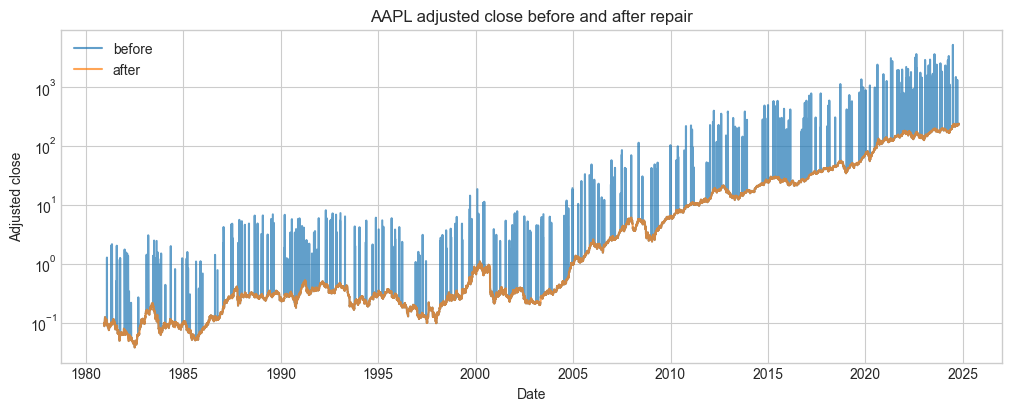

In [28]:
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for label, frame in [('before', deduplicated), ('after', cleaned)]:
    sample = frame.loc[frame['ticker'].eq('AAPL')]
    ax.plot(sample['ts'], sample['adj_close'], label=label, alpha=0.7)
ax.set(title='AAPL adjusted close before and after repair', xlabel='Date', ylabel='Adjusted close', yscale='log')
ax.legend()
plt.show()

**Before vs after:**
- `adj_close` max falls from 10,442 to 605.4 (the max `close`) and its mean from 51.65 to 37.27, as the inflated values are rebuilt.
- Missing `adj_close` falls from 19,855 (raw rows, duplicates included) to 0.
- The AAPL chart (log scale) shows the upward spikes before repair and a smooth series after.

### Save `ohlc_hw_cleaned`:
- `ts` is stored as ISO dates (`YYYY-MM-DD`) so the report's SQL date filters work.

- The repair flags and `raw_ticker` are saved with the cleaned data.

In [29]:
to_save = cleaned.copy()
to_save['ts'] = to_save['ts'].dt.strftime('%Y-%m-%d')
with closing(sqlite3.connect(db_path)) as conn:
    to_save.to_sql('ohlc_hw_cleaned', conn, if_exists='replace', index=False)
    display(pd.read_sql_query('SELECT COUNT(*) AS rows, COUNT(DISTINCT ticker) AS tickers, '
                              'MIN(ts) AS first, MAX(ts) AS last FROM ohlc_hw_cleaned', conn))

,rows,tickers,first,last
0,368251,30,1962-01-02,2024-12-06
